# RUNX1-ETS1 (combo 14_64) vs Shrivastava et al. 2014 (Leukemia, PDB 4L0Z)

**Findings** (100 high vs 100 low models, medians; paired by background)

1. **High motif packs the two TFs together more.** TF1-TF2 BSA 1,516 vs 1,047 Å² (high > low in 99/100 backgrounds, paired Wilcoxon p = 4e-18); vdW contacts 340 vs 169, H-bonds 9.5 vs 5. AF3 confidence in that interface does not change (TF-TF ipTM ~0.42 both; interface PAE ~19 Å both). DNA engagement barely changes (TF-DNA BSA 863 vs 835 Å², TF-DNA ipTM ~0.93 both, similar base-contact fraction) - the motif order changes how the proteins meet, not how each reads DNA.
2. **The extra contact is the RUNX1 EID engaging ETS1**, as the paper predicts. EID hydrophobic helix (F194/L198/L201) touches ETS1 in 99/100 high vs 0/100 low models; EID-Ets domain atom contacts 20 vs 0 (in low the EID sits ~45 Å away).
3. **But not the crystal binding mode.** EID is 14-22 Å from its 4L0Z position (after Ets-domain fit); R197-L422 is ~8 Å (crystal 2.7 Å H-bond); EID helix 2 arginines (R205/R206/R210) rarely reach the DNA. AF3 keeps the ETS1 inhibitory helices HI1/HI2 packed on the Ets domain in both classes (~60 contacts; disordered/displaced in the crystal) and the EID binds next to them. EID pLDDT is low (~47 high, ~54 low).
4. **Interpretation:** AF3 captures orientation-dependent EID recruitment but predicts autoinhibited ETS1 rather than the paper's activating IRM displacement. The crystal TCRα site has both sites on one strand, ETS 5' of RUNX (`CAGAG|GAT|GTGG|CTTC`: ETS core GGAT and RUNX TGTGG overlapping by 1 bp) - the **same orientation as our high motif** (`CAGGAAGT·TGTGGTT`, 2-bp gap), reversed in low - so high is the crystal-like arrangement, with different spacing.
5. **RMSD to 4L0Z (CA; all 200 models; paired high vs low).** Each domain's fold matches the crystal in both classes (Runt domain ~0.57 Å, Ets domain ~0.32 Å, no class difference). Each domain also sits on its own DNA site close to the crystal (superposed on the site backbone: Ets domain 1.9 Å high vs 1.1 Å low; Runt domain 2.8 vs 1.4 Å; low closer in 100/100, p = 4e-18) - i.e. packing the two TFs together in high slightly distorts each TF-DNA docking. DNA-contacting residues match the crystal (Runt domain 100% recall, Jaccard ~0.9; Ets domain ~90-95% recall, Jaccard ~0.75; no class difference). The relative placement of the two domains differs from the crystal in both classes (joint Runt+Ets RMSD 9.4 Å high vs 10.0 Å low; high closer in 100/100, p = 4e-18), as expected from the different site spacing; the EID is far closer to its crystal pose in high (16.6 vs 43.1 Å) but still not in it.
6. **Other RUNX1 pairs** (TF-TF BSA, paired): RUNX1-GABPA (other ETS partner) strongest high > low (+1,296 Å², 100/100); RUNX1-LEF1 (+245, 94/100) and RUNX1-TCF7 (+120, 86/100) high > low; RUNX1-IKZF1 weakly reversed (-64, 39/100); SPI1-RUNX1 reversed (-385, 5/100).

Note: the paper's "Arg208" is Ala in both UniProt Q01196 and 4L0Z; R210 (the third Arg of helix α2) is used instead.


In [1]:
import os
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
import seaborn as sns
from scipy.stats import wilcoxon
from Bio.PDB import MMCIFParser, NeighborSearch, Superimposer
import pymol2
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# RUNX1-ETS1 vs Shrivastava et al. 2014 Leukemia 28:2040 (doi:10.1038/leu.2014.111, PDB 4L0Y/4L0Z/4L18)
# crystal: Runx1(1-242) + Ets1(296-441) on TCRa enhancer DNA. Runx1 Ets1-interacting domain (EID, 189-212;
# helix a1 194-203 packs on the Ets domain, a2 204-211 lies on DNA) displaces the Ets1 inhibitory module (IRM)
# key EID residues: F194, L198, L201 (hydrophobic, into Ets1 depression), R197 (H-bond to Ets1 L422 O),
# R205/R206/R208 (against DNA phosphates) - residue 208 is Ala in both RUNX1 (Q01196) and 4L0Z,
# so the third Arg of helix a2 is R210; the paper's "Arg208" looks like a typo, R205/R206/R210 used here
# our models: full-length RUNX1 (453 aa, chain A) + full-length ETS1 (441 aa, chain B), same numbering as the paper
os.makedirs("../results/figures/runx1_ets1", exist_ok=True)

# domains as in Fig. 1a. RD/EID/IRM helices/phosphosites from the paper + UniProt (Q01196, P14921);
# TAD/ReD/SRR boundaries are approximate (literature, not stated in the paper text)
RUNX1_DOMAINS = [("N-term", 1, 49, "#c7e9c0"), ("RD", 50, 177, "#31a354"), ("EID", 189, 212, "#d62fd6"),
                 ("TAD", 291, 371, "#fdae6b"), ("ReD", 372, 411, "#9e9ac8")]
ETS1_DOMAINS = [("PNT", 51, 136, "#fdd0a2"), ("SRR", 244, 300, "#bdbdbd"), ("HI1", 304, 312, "#ff7f00"),
                ("HI2", 323, 330, "#ff7f00"), ("ED", 331, 415, "#1fb4c8"), ("H4", 418, 422, "#ff7f00"),
                ("H5", 426, 432, "#ff7f00")]
ETS1_PSITES = [251, 254, 270, 282, 285]
EID = range(189, 213)
ED = range(331, 416)
IRM_HELICES = list(range(304, 313)) + list(range(323, 331))
XTAL = "../data/pdb/4L0Z.cif"  # the crystal form with both EID helices traced (Runx1 54-212)

In [3]:
dt = pd.read_csv("../results/tables/bsa_n100_rho0.6_high_vs_low.csv")
dt = dt[dt["group"] == "RUNX1_ETS1_14_64"].copy()
dt["model_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + dt["name"] + "_model.cif"
dt["class"].value_counts()

class
high    100
low     100
Name: count, dtype: int64

In [4]:
# same representative models as notebook 4 (closest to the group-class median BSA)
reps = {}
for cls in ["high", "low"]:
    sub = dt[dt["class"] == cls]
    reps[cls] = sub.iloc[(sub["BSA"] - sub["BSA"].median()).abs().argsort().iloc[0]]["name"]
reps

{'high': 'RUNX1_ETS1_14_64_high_bg81', 'low': 'RUNX1_ETS1_14_64_low_bg30'}

In [5]:
parser = MMCIFParser(QUIET=True)

def yy_eid_metrics(model, runx1="A", ets1="B", dna=("C", "D")):
    """Per-residue contact sets + EID/IRM metrics for one RUNX1-ETS1-DNA structure."""
    atoms = [a for a in model.get_atoms() if a.element != "H" and a.get_parent().id[0] == " "]
    out = {"runx1_ets1": set(), "ets1_runx1": set(), "runx1_dna": set(), "ets1_dna": set(),
           "EID_ED_contacts": 0, "IRM_ED_contacts": 0, "core_res": set()}
    for a1, a2 in NeighborSearch(atoms).search_all(4.5, level="A"):
        c1, c2 = a1.get_parent().get_parent().id, a2.get_parent().get_parent().id
        r1, r2 = a1.get_parent().id[1], a2.get_parent().id[1]
        if {c1, c2} == {runx1, ets1}:
            rr, re_ = (r1, r2) if c1 == runx1 else (r2, r1)
            out["runx1_ets1"].add(rr)
            out["ets1_runx1"].add(re_)
            out["EID_ED_contacts"] += rr in EID and re_ in ED
            if rr in (194, 198, 201):
                out["core_res"].add(rr)
        elif c1 in dna and c2 in (runx1, ets1) or c2 in dna and c1 in (runx1, ets1):
            pc, pr = (c2, r2) if c1 in dna else (c1, r1)
            out["runx1_dna" if pc == runx1 else "ets1_dna"].add(pr)
        elif c1 == c2 == ets1 and abs(r1 - r2) > 3:
            out["IRM_ED_contacts"] += (r1 in IRM_HELICES and r2 in ED) or (r2 in IRM_HELICES and r1 in ED)
    # R197 side chain N to ETS1 L422 backbone O
    r197 = [model[runx1][197][n] for n in ("NE", "NH1", "NH2") if 197 in model[runx1] and n in model[runx1][197]]
    l422 = model[ets1][422]["O"] if 422 in model[ets1] else None
    out["R197_L422_dist"] = min(a - l422 for a in r197) if r197 and l422 is not None else np.nan
    # R205/R206/R210 guanidinium within 6 A of a DNA phosphate oxygen (long-range electrostatics)
    phos = [a for ch in dna for a in model[ch].get_atoms() if a.get_name() in ("OP1", "OP2")]
    ns_p = NeighborSearch(phos)
    out["EID_Arg_DNA"] = sum(
        any(ns_p.search(model[runx1][r][n].coord, 6.0) for n in ("NE", "NH1", "NH2") if n in model[runx1][r])
        for r in (205, 206, 210) if r in model[runx1])
    out["EID_core_contacts"] = len(out["core_res"])
    return out

def yy_eid_rmsd(model, xtal, runx1="A", ets1="B"):
    """Superpose on Ets domain CA (vs crystal), return EID CA RMSD without refitting."""
    ed = [r for r in ED if r in xtal[ets1] and r in model[ets1]]
    sup = Superimposer()
    sup.set_atoms([xtal[ets1][r]["CA"] for r in ed], [model[ets1][r]["CA"] for r in ed])
    rot, tran = sup.rotran
    eid = [r for r in EID if r in xtal[runx1] and r in model[runx1]]
    m = np.array([model[runx1][r]["CA"].coord for r in eid]) @ rot + tran
    x = np.array([xtal[runx1][r]["CA"].coord for r in eid])
    return np.sqrt(((m - x) ** 2).sum(axis=1).mean())

xtal = parser.get_structure("xtal", XTAL)[0]
xtal_m = yy_eid_metrics(xtal)
{k: v for k, v in xtal_m.items() if not isinstance(v, set)}

{'EID_ED_contacts': 67,
 'IRM_ED_contacts': 0,
 'R197_L422_dist': np.float32(2.6669276),
 'EID_Arg_DNA': 3,
 'EID_core_contacts': 3}

In [6]:
# all 200 RUNX1-ETS1 models (~1-2 min)
rows, freq = [], {}
for _, row in dt.iterrows():
    model = parser.get_structure(row["name"], row["model_path"])[0]
    m = yy_eid_metrics(model)
    rows.append({"name": row["name"], "class": row["class"], "background_idx": row["background_idx"],
                 "BSA": row["BSA"], "iptm_AB": row["iptm_AB"],
                 "EID_ED_contacts": m["EID_ED_contacts"], "EID_core_contacts": m["EID_core_contacts"],
                 "R197_L422_dist": m["R197_L422_dist"], "EID_Arg_DNA": m["EID_Arg_DNA"],
                 "IRM_ED_contacts": m["IRM_ED_contacts"],
                 "EID_pLDDT": np.mean([model["A"][r]["CA"].bfactor for r in EID]),
                 "IRM_pLDDT": np.mean([model["B"][r]["CA"].bfactor for r in IRM_HELICES]),
                 "EID_RMSD_vs_4L0Z": yy_eid_rmsd(model, xtal)})
    for key, n in [("runx1_ets1", 453), ("ets1_runx1", 441), ("runx1_dna", 453), ("ets1_dna", 441)]:
        freq.setdefault((row["class"], key), np.zeros(n + 1))
        freq[(row["class"], key)][list(m[key])] += 1

metrics = pd.DataFrame(rows)
for k in freq:
    freq[k] = freq[k] / (metrics["class"] == k[0]).sum()
metrics.to_csv("../results/tables/runx1_ets1_eid_metrics_vs_4L0Z.csv", index=False)
metrics.head()

,name,class,background_idx,BSA,iptm_AB,EID_ED_contacts,EID_core_contacts,R197_L422_dist,EID_Arg_DNA,IRM_ED_contacts,EID_pLDDT,IRM_pLDDT,EID_RMSD_vs_4L0Z
0,RUNX1_ETS1_14_64_high_bg61,high,61,2011.775951,0.42,20,3,7.790968,0,58,46.412917,57.805882,16.028950
1,RUNX1_ETS1_14_64_high_bg15,high,15,1995.658393,0.42,19,3,7.628847,0,57,46.401667,58.514118,15.921399
2,RUNX1_ETS1_14_64_high_bg78,high,78,1970.484767,0.42,16,3,7.483018,0,60,46.692083,58.831176,14.991287
3,RUNX1_ETS1_14_64_high_bg43,high,43,1836.489551,0.43,17,3,7.458218,0,58,46.736667,58.588824,15.572395
4,RUNX1_ETS1_14_64_high_bg42,high,42,1824.783393,0.42,17,3,7.753532,0,58,46.838333,58.392353,15.299517


In [7]:
metrics.groupby("class")[["EID_ED_contacts", "EID_core_contacts", "R197_L422_dist", "EID_Arg_DNA",
                          "IRM_ED_contacts", "EID_pLDDT", "IRM_pLDDT", "EID_RMSD_vs_4L0Z"]].describe().T.round(2)

class                     high     low
EID_ED_contacts  count  100.00  100.00
                 mean    26.36    0.84
                 std     10.36    3.34
                 min      7.00    0.00
                 25%     17.75    0.00
...                        ...     ...
EID_RMSD_vs_4L0Z min     14.19   37.17
                 25%     15.32   41.80
                 50%     15.76   43.66
                 75%     21.79   44.82
                 max     22.56   46.90

[64 rows x 2 columns]

In [8]:
# crystal-like EID docking: alpha1 core (F194/L198/L201) all touching ETS1 and EID within 4 A of crystal pose
metrics["EID_docked_like_4L0Z"] = (metrics["EID_core_contacts"] == 3) & (metrics["EID_RMSD_vs_4L0Z"] < 4)
pd.crosstab(metrics["class"], metrics["EID_docked_like_4L0Z"])

EID_docked_like_4L0Z,False
class,
high,100
low,100


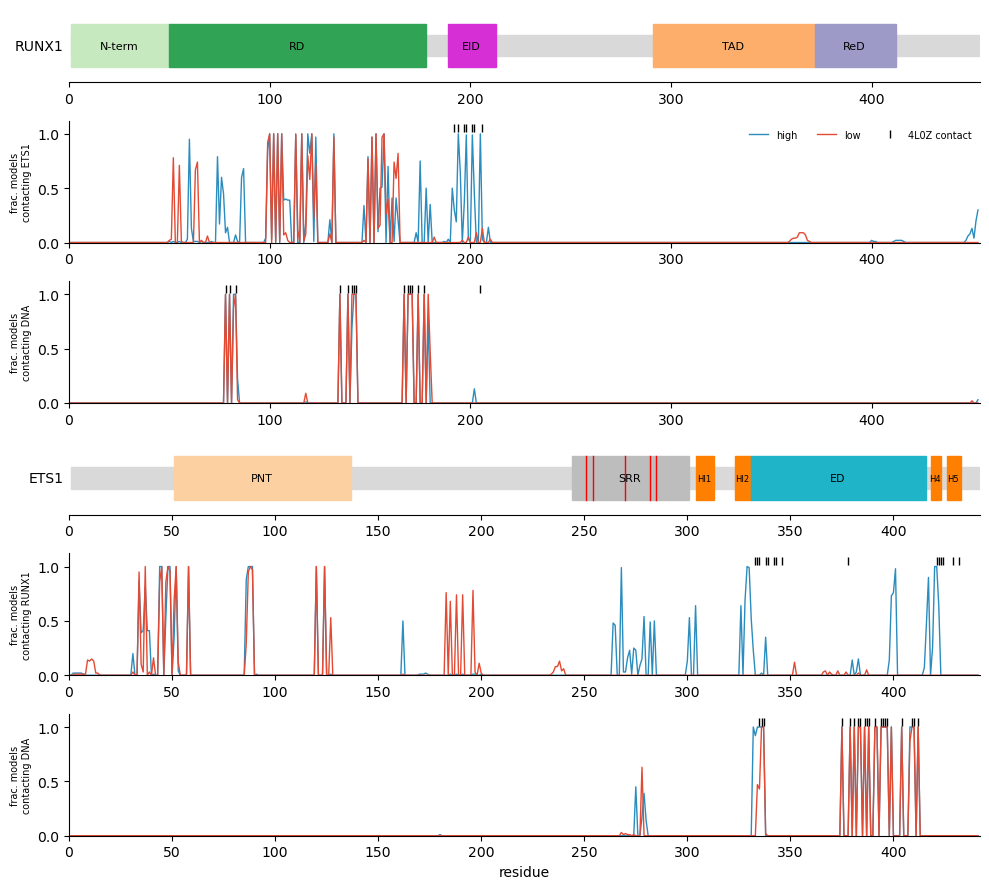

In [9]:
# Fig. 1a-like: domain maps + per-residue contact frequency over the 100 models per class
palette = {"high": "#2b8cbe", "low": "#e34a33"}

def yy_domain_bar(ax, domains, length, name, psites=()):
    ax.add_patch(Rectangle((1, 0.35), length, 0.3, color="0.85"))
    for lab, s, e, col in domains:
        ax.add_patch(Rectangle((s, 0.2), e - s + 1, 0.6, color=col))
        ax.text((s + e) / 2, 0.5, lab, ha="center", va="center", fontsize=6 if e - s < 15 else 8)
    for p in psites:
        ax.plot([p, p], [0.2, 0.8], color="red", lw=1)
    ax.set_xlim(0, length + 1)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)

def yy_freq_track(ax, key, length, xtal_res, ylabel):
    x = np.arange(length + 1)
    for cls in ["high", "low"]:
        ax.plot(x, freq[(cls, key)], color=palette[cls], lw=1, label=cls)
    ax.plot(sorted(xtal_res), np.full(len(xtal_res), 1.05), "|", color="k", ms=6, label="4L0Z contact")
    ax.set_xlim(0, length + 1)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel(ylabel, fontsize=7)
    sns.despine(ax=ax)

fig, axes = plt.subplots(6, 1, figsize=(10, 9), sharex=False,
                         gridspec_kw={"height_ratios": [0.6, 1, 1, 0.6, 1, 1]})
yy_domain_bar(axes[0], RUNX1_DOMAINS, 453, "RUNX1")
yy_freq_track(axes[1], "runx1_ets1", 453, xtal_m["runx1_ets1"], "frac. models\ncontacting ETS1")
yy_freq_track(axes[2], "runx1_dna", 453, xtal_m["runx1_dna"], "frac. models\ncontacting DNA")
yy_domain_bar(axes[3], ETS1_DOMAINS, 441, "ETS1", ETS1_PSITES)
yy_freq_track(axes[4], "ets1_runx1", 441, xtal_m["ets1_runx1"], "frac. models\ncontacting RUNX1")
yy_freq_track(axes[5], "ets1_dna", 441, xtal_m["ets1_dna"], "frac. models\ncontacting DNA")
axes[1].legend(fontsize=7, frameon=False, ncol=3, loc="upper right")
axes[5].set_xlabel("residue")
plt.tight_layout()
plt.savefig("../results/figures/runx1_ets1/fig1a_like_domains_contact_frequency.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [10]:
# Fig. 1b / 2a-like PyMOL renders: models superposed on the crystal via the Ets domain (CA 334-415),
# so the crystal view is reused for every panel. shown: crystal-resolved regions (RUNX1 50-215, ETS1 296-441)
def yy_color_domains(cmd, obj):
    cmd.color("0xe5f5e0", f"{obj} and chain A")
    cmd.color("0xd9f0f7", f"{obj} and chain B")
    for lab, s, e, col in RUNX1_DOMAINS:
        cmd.color("0x" + col[1:], f"{obj} and chain A and resi {s}-{e}")
    for lab, s, e, col in ETS1_DOMAINS:
        cmd.color("0x" + col[1:], f"{obj} and chain B and resi {s}-{e}")
    cmd.color("grey60", f"{obj} and chain C+D and elem C")

panels = {"4L0Z crystal (TCRα)": XTAL}
for cls in ["high", "low"]:
    panels[f"{cls}: {reps[cls]}"] = f"../af3_screen_n100_rho0.6/outputs_inference/{reps[cls]}_model.cif"

def yy_prefix(cif):
    return "../results/figures/runx1_ets1/render_" + os.path.basename(cif).replace("_model.cif", "").replace(".cif", "")

# all panels in one PyMOL session so they share one view and one zoom (fitted to everything shown,
# so nothing is clipped and the scale is the same across panels)
def yy_render_panels(width=1000, height=800):
    p = pymol2.PyMOL()
    p.start()
    cmd = p.cmd
    objs = {}
    for i, cif in enumerate(panels.values()):
        obj = f"p{i}"
        cmd.load(cif, obj)
        cmd.remove(f"{obj} and (solvent or resn GOL)")
        if i > 0:
            cmd.align(f"{obj} and chain B and resi 334-415 and name CA", "p0 and chain B and resi 334-415 and name CA", cycles=0)
        objs[obj] = yy_prefix(cif)
    cmd.bg_color("white")
    cmd.set("ray_opaque_background", 0)
    cmd.set("stick_radius", 0.2)
    cmd.set("label_size", 15)
    cmd.set("label_color", "black")
    cmd.set("label_position", (0, 0, 12))
    cmd.set("label_outline_color", "white")
    cmd.set("label_font_id", 7)
    cmd.hide("everything")
    for obj in objs:
        cmd.show("cartoon", f"{obj} and ((chain A and resi 50-215) or (chain B and resi 296-441))")
        cmd.show("sticks", f"{obj} and chain C+D and not elem H")
        yy_color_domains(cmd, obj)

    def snap(suffix):
        for obj, prefix in objs.items():
            cmd.disable("all")
            cmd.enable(obj)
            cmd.png(f"{prefix}_{suffix}.png", width=width, height=height, dpi=150, ray=1)
        cmd.enable("all")

    # overall, two orientations (Fig. 1b)
    cmd.orient("p0 and polymer")
    cmd.zoom("rep cartoon or rep sticks", buffer=2, complete=1)
    snap("view1")
    cmd.turn("x", 90)
    cmd.zoom("rep cartoon or rep sticks", buffer=2, complete=1)
    snap("view2")

    # EID-Ets domain close-up (Fig. 2a), centred on the crystal EID position
    key = "((chain A and resi 194+197+198+201+205+206+210) or (chain B and resi 422)) and not name N+C+O"
    cmd.show("sticks", key)
    cmd.label(f"{key} and ((resn PHE+ARG and name CZ) or (resn LEU and name CG))", '"%s%s" % (oneletter, resi)')
    cmd.orient("p0 and chain A and resi 189-212")
    cmd.zoom("(chain A and resi 189-212) or (p0 and chain B and resi 331-441 and rep cartoon)", buffer=3, complete=1)
    snap("closeup")
    p.stop()

yy_render_panels()

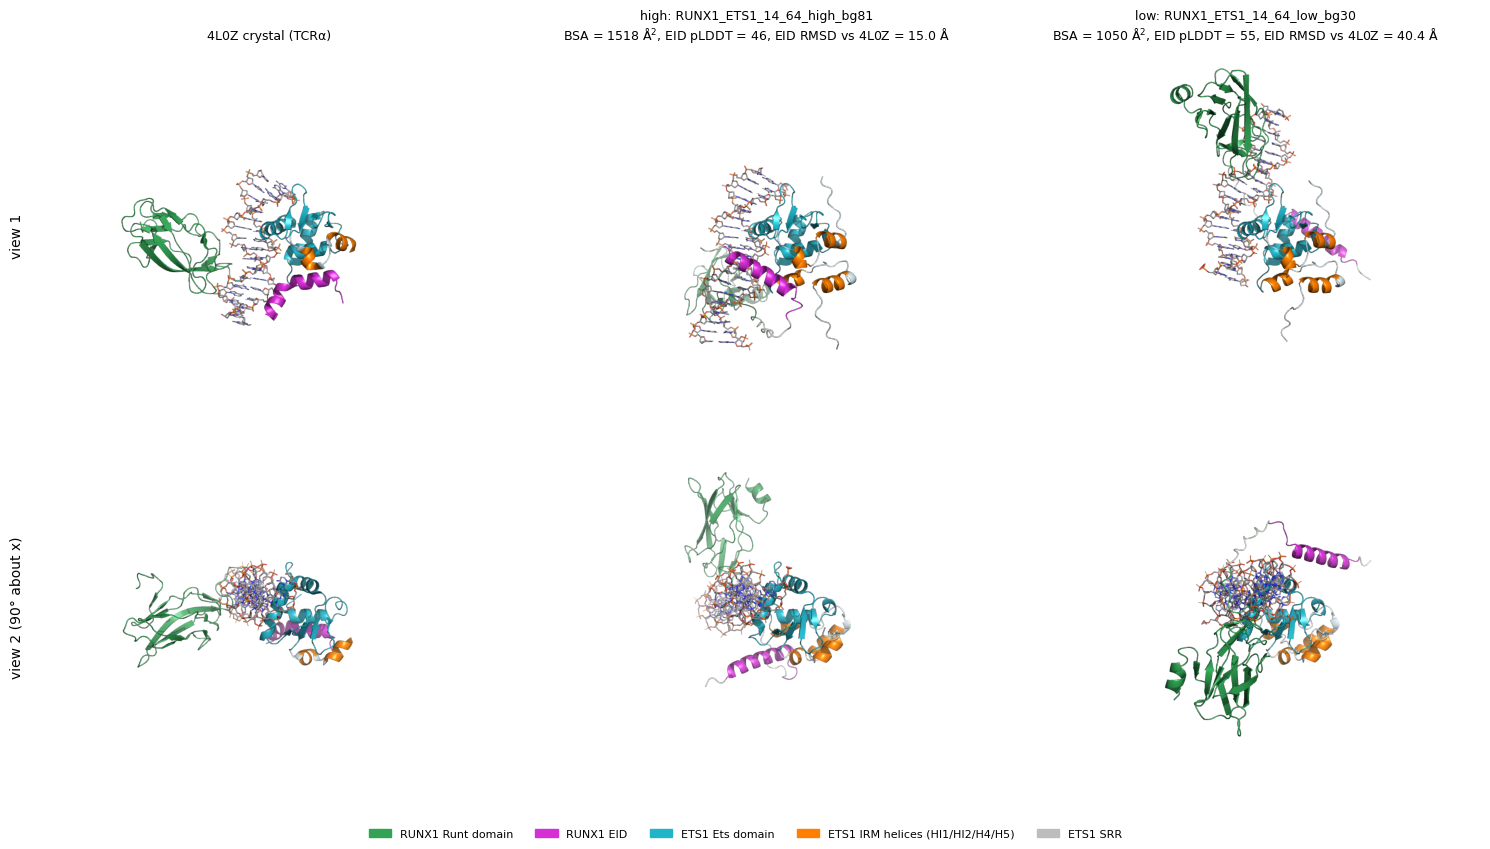

In [11]:
legend_handles = [Rectangle((0, 0), 1, 1, color=c) for c in ["#31a354", "#d62fd6", "#1fb4c8", "#ff7f00", "#bdbdbd"]]
legend_labels = ["RUNX1 Runt domain", "RUNX1 EID", "ETS1 Ets domain", "ETS1 IRM helices (HI1/HI2/H4/H5)", "ETS1 SRR"]

def yy_panel_grid(views, out_pdf, row_labels):
    fig, axes = plt.subplots(len(views), len(panels), figsize=(5 * len(panels), 4.2 * len(views)))
    axes = np.atleast_2d(axes)
    for j, (title, cif) in enumerate(panels.items()):
        prefix = yy_prefix(cif)
        for i, v in enumerate(views):
            axes[i, j].imshow(mpimg.imread(f"{prefix}_{v}.png"))
            axes[i, j].axis("off")
        name = title.split(": ")[-1]
        sub = metrics[metrics["name"] == name]
        extra = "" if sub.empty else (f"\nBSA = {sub['BSA'].iloc[0]:.0f} Å$^2$, EID pLDDT = {sub['EID_pLDDT'].iloc[0]:.0f}, "
                                      f"EID RMSD vs 4L0Z = {sub['EID_RMSD_vs_4L0Z'].iloc[0]:.1f} Å")
        axes[0, j].set_title(title + extra, fontsize=9)
    for i, lab in enumerate(row_labels):
        axes[i, 0].text(-0.02, 0.5, lab, transform=axes[i, 0].transAxes, rotation=90, ha="right", va="center")
    fig.legend(legend_handles, legend_labels, loc="lower center", ncol=5, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.savefig(out_pdf, bbox_inches='tight')
    plt.show()
    plt.close()

yy_panel_grid(["view1", "view2"], "../results/figures/runx1_ets1/fig1b_like_overall_structure.pdf", ["view 1", "view 2 (90° about x)"])

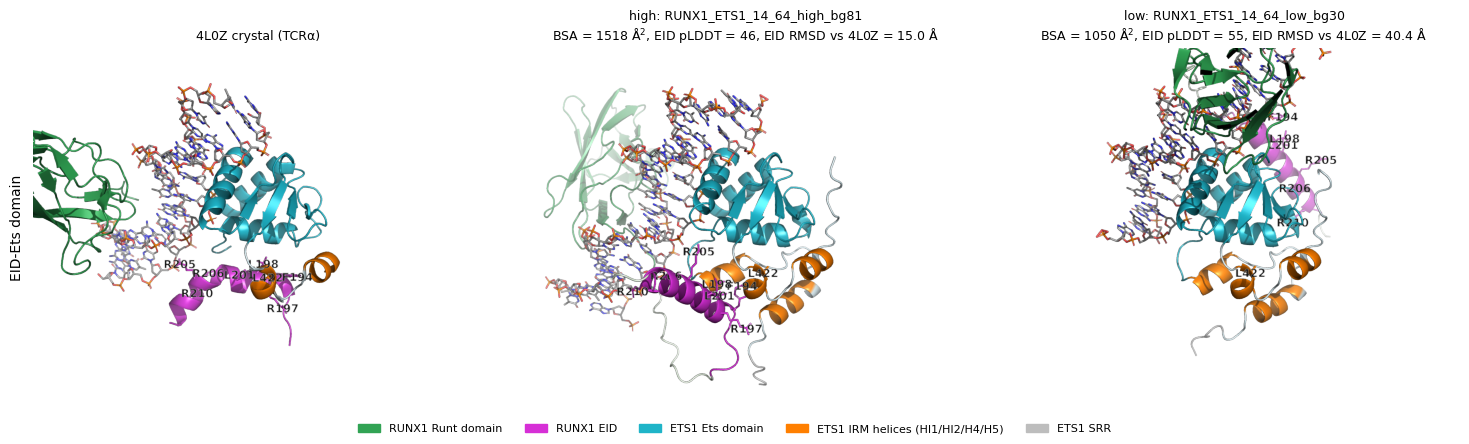

In [12]:
yy_panel_grid(["closeup"], "../results/figures/runx1_ets1/fig2a_like_EID_Ets_interface.pdf", ["EID-Ets domain"])

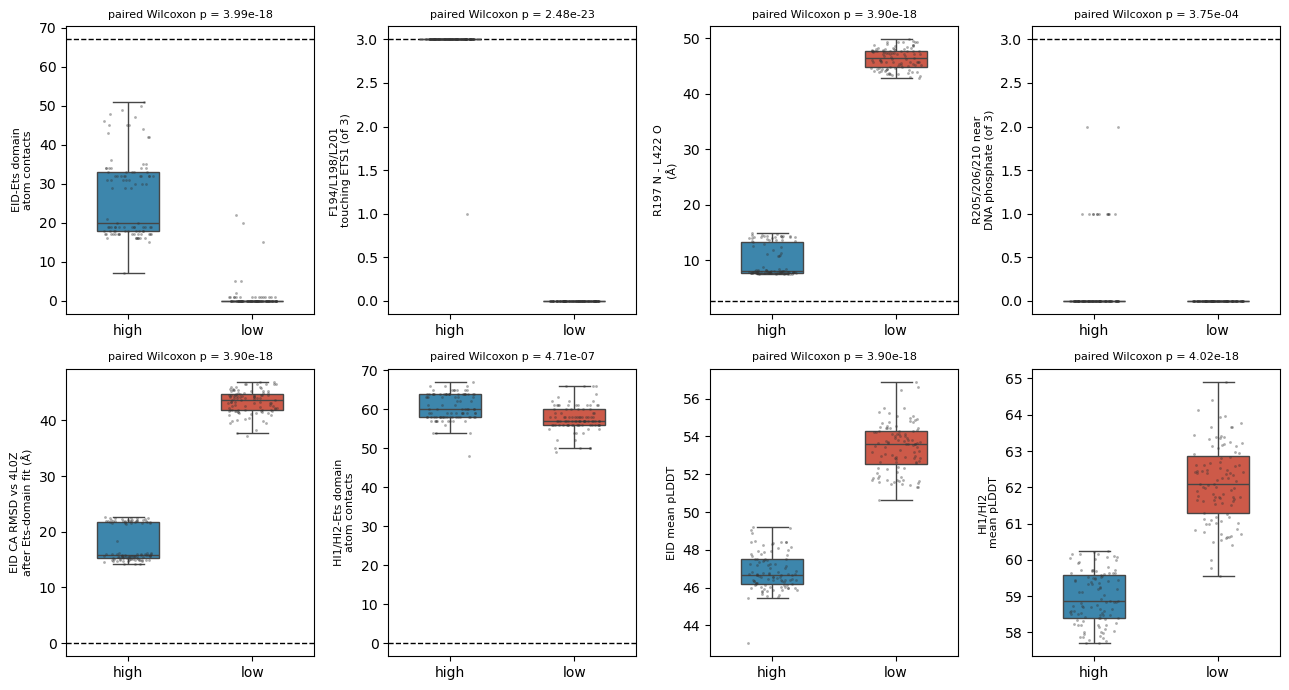

In [13]:
# quantitative: does AF3 recapitulate the crystal EID-Ets1 interface, and is it better with the high motif?
cols = [("EID_ED_contacts", "EID-Ets domain\natom contacts"), ("EID_core_contacts", "F194/L198/L201\ntouching ETS1 (of 3)"),
        ("R197_L422_dist", "R197 N - L422 O\n(Å)"), ("EID_Arg_DNA", "R205/206/210 near\nDNA phosphate (of 3)"),
        ("EID_RMSD_vs_4L0Z", "EID CA RMSD vs 4L0Z\nafter Ets-domain fit (Å)"), ("IRM_ED_contacts", "HI1/HI2-Ets domain\natom contacts"),
        ("EID_pLDDT", "EID mean pLDDT"), ("IRM_pLDDT", "HI1/HI2\nmean pLDDT")]
xtal_ref = {"EID_ED_contacts": xtal_m["EID_ED_contacts"], "EID_core_contacts": xtal_m["EID_core_contacts"],
            "R197_L422_dist": xtal_m["R197_L422_dist"], "EID_Arg_DNA": xtal_m["EID_Arg_DNA"],
            "EID_RMSD_vs_4L0Z": 0, "IRM_ED_contacts": xtal_m["IRM_ED_contacts"]}

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, (col, label) in zip(axes.flat, cols):
    sns.boxplot(data=metrics, x="class", y=col, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=metrics, x="class", y=col, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.4, ax=ax)
    if col in xtal_ref:
        ax.axhline(xtal_ref[col], ls="--", color="k", lw=1)
    paired = metrics.pivot_table(index="background_idx", columns="class", values=col).dropna()
    p_value = wilcoxon(paired["high"], paired["low"]).pvalue if (paired["high"] != paired["low"]).any() else 1
    ax.set_title(f"paired Wilcoxon p = {p_value:.2e}", fontsize=8)
    ax.set_ylabel(label, fontsize=8)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../results/figures/runx1_ets1/eid_interface_metrics_high_vs_low_vs_4L0Z.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [14]:
# RMSD of every RUNX1-ETS1 model to the crystal (4L0Z), CA atoms, numbering shared with the crystal
#   RD_fold / ED_fold: each domain superposed on itself (is the fold right?)
#   ED_on_ETS_site / RD_on_RUNX_site: superpose on the backbone of the bound DNA site (GGAA / TGTGG strand,
#     C1'/C3'/C4'), domain RMSD without refit (does each TF sit on its site as in the crystal?)
#   RD_after_ED_fit / RD_ED_joint: relative placement of the two DNA-binding domains - depends on the site
#     arrangement (crystal: ETS then RUNX on one strand, 1-bp overlap; high: same order, 2-bp gap; low: reversed)
#   EID_after_ED_fit: as above (Fig. 2a interface)
RD = range(54, 178)  # resolved in 4L0Z chain A
ED_CA = range(334, 416)
SITE_ATOMS = ("C1'", "C3'", "C4'")
# crystal TCRa: both sites on strand D (CAGAG|GAT|GTGG|CTTC): ETS core GGAT = D105-108, RUNX TGTGG = D108-112
# (1-bp overlap) - same orientation as our high motif (ETS 5' of RUNX, same strand), different spacing
xtal_sites = {"ETS": ("D", range(105, 109)), "RUNX": ("D", range(108, 113))}

def yy_ca(model, chain, res):
    return [model[chain][r]["CA"] for r in res if r in model[chain] and "CA" in model[chain][r]]

def yy_rmsd_after_fit(fix, mov, fit_fix, fit_mov):
    """Superpose fit_mov onto fit_fix, return RMSD between fix and transformed mov (lists of matched atoms)."""
    sup = Superimposer()
    sup.set_atoms(fit_fix, fit_mov)
    rot, tran = sup.rotran
    m = np.array([a.coord for a in mov]) @ rot + tran
    x = np.array([a.coord for a in fix])
    return np.sqrt(((m - x) ** 2).sum(axis=1).mean())

def yy_site_atoms(model, chain, res):
    return [model[chain][r][n] for r in res for n in SITE_ATOMS]

def yy_matched(model, chain, res):
    res = [r for r in res if r in xtal[chain] and "CA" in xtal[chain][r] and r in model[chain] and "CA" in model[chain][r]]
    return yy_ca(xtal, chain, res), yy_ca(model, chain, res)

seqs = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv")
seqs = seqs[(seqs["TF1"] == "RUNX1") & (seqs["TF2"] == "ETS1")].set_index(["class", "background_idx"])

rows = []
for _, row in dt.iterrows():
    model = parser.get_structure(row["name"], row["model_path"])[0]
    s = seqs.loc[(row["class"], row["background_idx"])]
    off = s["sequence"].find(s["composite_motif"]) + 1  # chain C residue id of the composite start
    ets_start = off + s["composite_motif"].find("GGAA")  # GGAA (model) vs GGAT (crystal): backbone atoms only
    runx_start = off + s["composite_motif"].find("TGTGG")
    x_rd, m_rd = yy_matched(model, "A", RD)
    x_ed, m_ed = yy_matched(model, "B", ED_CA)
    x_eid, m_eid = yy_matched(model, "A", EID)
    x_ets = yy_site_atoms(xtal, *xtal_sites["ETS"])
    m_ets = yy_site_atoms(model, "C", range(ets_start, ets_start + 4))
    x_runx = yy_site_atoms(xtal, *xtal_sites["RUNX"])
    m_runx = yy_site_atoms(model, "C", range(runx_start, runx_start + 5))
    rows.append({
        "name": row["name"], "class": row["class"], "background_idx": row["background_idx"],
        "RD_fold": yy_rmsd_after_fit(x_rd, m_rd, x_rd, m_rd),
        "ED_fold": yy_rmsd_after_fit(x_ed, m_ed, x_ed, m_ed),
        "ED_on_ETS_site": yy_rmsd_after_fit(x_ed, m_ed, x_ets, m_ets),
        "RD_on_RUNX_site": yy_rmsd_after_fit(x_rd, m_rd, x_runx, m_runx),
        "RD_after_ED_fit": yy_rmsd_after_fit(x_rd, m_rd, x_ed, m_ed),
        "RD_ED_joint": yy_rmsd_after_fit(x_rd + x_ed, m_rd + m_ed, x_rd + x_ed, m_rd + m_ed),
        "EID_after_ED_fit": yy_rmsd_after_fit(x_eid, m_eid, x_ed, m_ed),
    })
rmsd = pd.DataFrame(rows)
rmsd.to_csv("../results/tables/runx1_ets1_rmsd_vs_4L0Z.csv", index=False)
rmsd.groupby("class").median(numeric_only=True).drop(columns="background_idx").T.round(2)

class,high,low
RD_fold,0.57,0.56
ED_fold,0.32,0.31
ED_on_ETS_site,1.91,1.06
RD_on_RUNX_site,2.79,1.45
RD_after_ED_fit,44.13,50.10
RD_ED_joint,9.37,10.03
EID_after_ED_fit,16.64,43.13


In [15]:
rmsd_cols = ["RD_fold", "ED_fold", "RD_on_RUNX_site", "ED_on_ETS_site", "RD_after_ED_fit", "RD_ED_joint", "EID_after_ED_fit"]
paired = rmsd.pivot_table(index="background_idx", columns="class", values=rmsd_cols)
rmsd_stats = pd.DataFrame([{
    "metric": c, "median_high": paired[(c, "high")].median(), "median_low": paired[(c, "low")].median(),
    "n_high_lower": int((paired[(c, "high")] < paired[(c, "low")]).sum()),
    "paired_wilcoxon_p": wilcoxon(paired[(c, "high")], paired[(c, "low")]).pvalue} for c in rmsd_cols])
rmsd_stats.to_csv("../results/tables/runx1_ets1_rmsd_vs_4L0Z_high_vs_low.csv", index=False)
rmsd_stats.round(4)

,metric,median_high,median_low,n_high_lower,paired_wilcoxon_p
0,RD_fold,0.5712,0.5571,44,0.2033
1,ED_fold,0.3184,0.3149,36,0.0130
2,RD_on_RUNX_site,2.7907,1.4450,0,0.0000
3,ED_on_ETS_site,1.9138,1.0633,0,0.0000
4,RD_after_ED_fit,44.1274,50.1019,100,0.0000
5,RD_ED_joint,9.3735,10.0336,100,0.0000
6,EID_after_ED_fit,16.6387,43.1327,100,0.0000


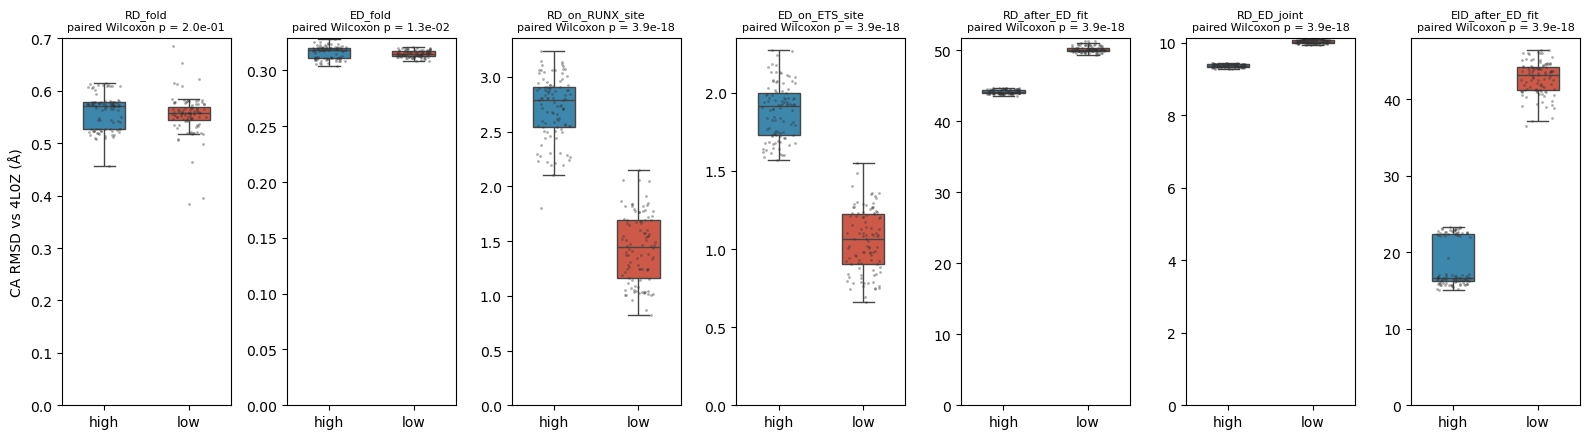

In [16]:
fig, axes = plt.subplots(1, len(rmsd_cols), figsize=(16, 4.5))
for ax, col in zip(axes, rmsd_cols):
    sns.boxplot(data=rmsd, x="class", y=col, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=rmsd, x="class", y=col, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.4, ax=ax)
    p_value = rmsd_stats.set_index("metric").loc[col, "paired_wilcoxon_p"]
    ax.set_title(f"{col}\npaired Wilcoxon p = {p_value:.1e}", fontsize=8)
    ax.set_ylabel("CA RMSD vs 4L0Z (Å)" if col == rmsd_cols[0] else "")
    ax.set_xlabel("")
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig("../results/figures/runx1_ets1/rmsd_vs_4L0Z_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [17]:
# DNA-contacting residues (heavy atom <= 4.5 A) of each DNA-binding domain vs the crystal
xs = {"A": {r for r in xtal_m["runx1_dna"] if r in range(50, 178)}, "B": {r for r in xtal_m["ets1_dna"] if r in range(331, 416)}}
dna_rows = []
for _, row in dt.iterrows():
    m = yy_eid_metrics(parser.get_structure(row["name"], row["model_path"])[0])
    r = {"name": row["name"], "class": row["class"], "background_idx": row["background_idx"]}
    for ch, key, lab in [("A", "runx1_dna", "RD"), ("B", "ets1_dna", "ED")]:
        dom = range(50, 178) if ch == "A" else range(331, 416)
        got = {x for x in m[key] if x in dom}
        r[f"{lab}_dna_jaccard_vs_4L0Z"] = len(got & xs[ch]) / len(got | xs[ch])
        r[f"{lab}_dna_recall_vs_4L0Z"] = len(got & xs[ch]) / len(xs[ch])
    dna_rows.append(r)
dna_cmp = pd.DataFrame(dna_rows)
dna_cmp.to_csv("../results/tables/runx1_ets1_dna_contacts_vs_4L0Z.csv", index=False)
dna_cmp.groupby("class").median(numeric_only=True).drop(columns="background_idx").T.round(2)

class,high,low
RD_dna_jaccard_vs_4L0Z,0.90,0.93
RD_dna_recall_vs_4L0Z,1.00,1.00
ED_dna_jaccard_vs_4L0Z,0.73,0.78
ED_dna_recall_vs_4L0Z,0.95,0.90
